# Lab 05: ADC Capture & the OTR Sticky Status Register

**Objective:** Register the 8-bit MS9280 ADC data bus in the **30.720 MHz** FPGA clock domain (`clk_30m`), forward the sample clock (`adc_clk`), and implement a clocked **sticky `OTR` interrupt register (`fpga_int`)** for the hardware-to-software AGC handshake with the Pico.

### AI Use Policy
Chat-based AI is permitted for explanations, design suggestions, or code generated from your written blueprint. **Agentic AI is not permitted.** You must edit the files yourself (e.g., with `vi`), run the simulations, test the edge cases, and be able to explain all submitted work.

## 1. Environment & Toolchain Preflight

Run this cell to confirm that `iverilog` and `vvp` are available for simulation, and check whether optional iCE40 synthesis tools (`yosys`, `nextpnr-ice40`, `icepack`) and the Lab 04 SPI parser (`../Lab_04/spi_cmd_parser.sv`) are present.

In [ ]:
import shutil
from pathlib import Path

tools = ["iverilog", "vvp", "yosys", "nextpnr-ice40", "icepack"]
print("=== Toolchain Check ===")
for tool in tools:
    loc = shutil.which(tool)
    if loc:
        print(f"  {tool:15s}: OK ({loc})")
    elif tool in ("iverilog", "vvp"):
        print(f"  {tool:15s}: MISSING (required for simulation)")
    else:
        print(f"  {tool:15s}: not found (optional for synthesis)")

lab04 = Path("../Lab_04/spi_cmd_parser.sv")
print("\n=== Lab 04 Dependency (for lab05_top.sv synthesis) ===")
print(f"  {lab04}: {'FOUND' if lab04.exists() else 'not found (needed only for synthesis)'}")

## 2. Hardware Contract & Architecture Blueprint

### Pin & Signal Contract (Dev-iCE)
| Signal | Direction | FPGA Pin(s) | Contract |
| :--- | :--- | :--- | :--- |
| `clk_30m` | Input | Master clock | 30.720 MHz (~32.55 ns period) |
| `reset_n` | Input | Pin 21 (`PMOD_0`, standalone) | Active-low async reset (prod pin 8 is not user reset) |
| `adc_clk` | Output | Pin 23 | Forwarded 30.720 MHz clock to MS9280 ADC |
| `adc_data_in[7:0]` | Input | Pins 25, 26, 27, 28, 31, 32, 34, 35 | Raw 8-bit ADC bus (modeled synchronous to `clk_30m`) |
| `adc_otr_in` | Input | Pin 36 | Active-high Out-of-Range (clipping) input |
| `cmd_clear_otr` | Input | Internal (Lab 04 SPI) | 1-cycle clear pulse from SPI command `0x04` (`D5 01 04 04 01 00 00 00`) |
| `adc_data_out[7:0]` | Output | Internal DSP | Registered ADC data (1-cycle pipeline delay) |
| `fpga_int` | Output | Pin 13 | Active-high sticky interrupt to Pico GPIO 0 |

> **Synchronous Assumption:** This design treats `adc_otr_in` as a synchronous input sampled on `posedge clk_30m`. A pulse occurring entirely between clock edges is not guaranteed to be caught without a separate asynchronous pulse-capture and metastability synchronizer.


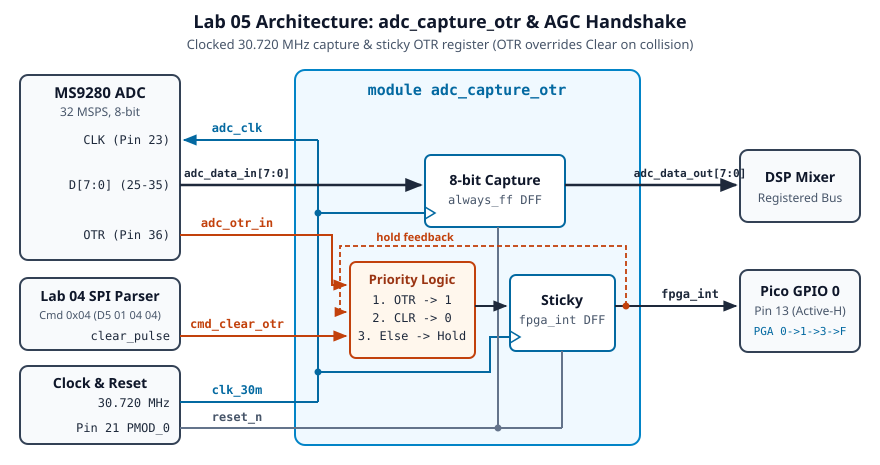


> **Why `always_ff` instead of a combinational SR latch?**
> An unclocked SR latch in FPGA LUT fabric introduces combinational feedback loops, glitch sensitivity, and broken static timing analysis in `nextpnr-ice40`. Using `always_ff @(posedge clk_30m or negedge reset_n)` guarantees glitch-free synchronous state transitions and clean timing closure at 30.720 MHz.

## 3. Priority Collision Timing Diagram (Spec vs. Buggy RTL)

Study the exact clock-by-clock behavior required across all four testbench edge cases before writing your RTL:
1. **Data Alignment:** `0x01`, `0x02`, `0x03` appear on `adc_data_out` exactly **1 clock edge** after `adc_data_in`.
2. **1-Cycle Catch & Hold:** A single-cycle `adc_otr_in` pulse sets `fpga_int` HIGH until cleared.
3. **Clear:** A 1-cycle `cmd_clear_otr` pulse drops `fpga_int` LOW on the next rising edge.
4. **Collision (`T5`):** Both `adc_otr_in` and `cmd_clear_otr` are HIGH on the same rising clock edge—**`fpga_int` must remain HIGH (`1`)** in the spec design, whereas a buggy clear-priority design drops to `0` and silently misses active clipping.


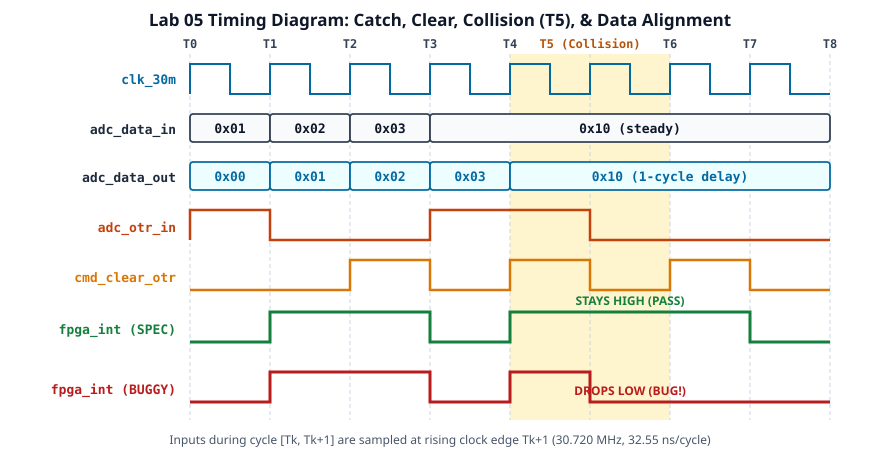

## 4. Behavioral Model Verification (Pure Python Stdlib)

Run this standard-library Python model to double-check the truth table for `fpga_int` before implementing your SystemVerilog modules.

In [ ]:
def next_fpga_int_spec(current_int: int, otr: int, clear: int) -> int:
    if otr:
        return 1
    if clear:
        return 0
    return current_int

def next_fpga_int_buggy(current_int: int, otr: int, clear: int) -> int:
    if clear:
        return 0
    if otr:
        return 1
    return current_int

print("cur | otr clr | spec | buggy")
print("----+---------+------+------")
for cur in (0, 1):
    for otr in (0, 1):
        for clr in (0, 1):
            s = next_fpga_int_spec(cur, otr, clr)
            b = next_fpga_int_buggy(cur, otr, clr)
            flag = "  <-- COLLISION!" if (otr and clr) else ""
            print(f" {cur}  |  {otr}   {clr}  |  {s}   |   {b}{flag}")

## 5. Step-by-Step RTL & Testbench Setup

### Step 5.1: Generate Starter Scaffolds (Safe Non-Clobbering)
Run the cell below to create starter templates for `adc_capture_otr.sv`, `adc_capture_otr_buggy.sv`, and `adc_capture_tb.sv` **if they do not already exist**. (To reset a template later, delete the file first.)

Then open each file in `vi` from your terminal and complete the `TODO` sections:
```sh
vi adc_capture_otr.sv
vi adc_capture_otr_buggy.sv
vi adc_capture_tb.sv
```

In [ ]:
from pathlib import Path

ADC_CAPTURE_OTR_TEMPLATE = """`timescale 1ns/1ps

module adc_capture_otr (
    input  logic       clk_30m,
    input  logic       reset_n,
    input  logic [7:0] adc_data_in,
    input  logic       adc_otr_in,
    input  logic       cmd_clear_otr,
    output logic       adc_clk,
    output logic [7:0] adc_data_out,
    output logic       fpga_int
);
    // Forward 30.720 MHz master clock to MS9280 ADC
    assign adc_clk = clk_30m;

    // Synchronous capture and sticky OTR register (active-low async reset)
    always_ff @(posedge clk_30m or negedge reset_n) begin
        if (!reset_n) begin
            adc_data_out <= 8'h00;
            fpga_int     <= 1'b0;
        end else begin
            // TODO 1: Register adc_data_in into adc_data_out


            // TODO 2: Implement sticky OTR logic for fpga_int
            // Priority: adc_otr_in wins over cmd_clear_otr; otherwise hold

        end
    end

endmodule
"""

ADC_CAPTURE_BUGGY_TEMPLATE = """`timescale 1ns/1ps

// Intentional mutation: keeps module name `adc_capture_otr` so the same
// testbench can verify that clear-over-OTR priority is caught as a failure.
module adc_capture_otr (
    input  logic       clk_30m,
    input  logic       reset_n,
    input  logic [7:0] adc_data_in,
    input  logic       adc_otr_in,
    input  logic       cmd_clear_otr,
    output logic       adc_clk,
    output logic [7:0] adc_data_out,
    output logic       fpga_int
);
    assign adc_clk = clk_30m;

    always_ff @(posedge clk_30m or negedge reset_n) begin
        if (!reset_n) begin
            adc_data_out <= 8'h00;
            fpga_int     <= 1'b0;
        end else begin
            adc_data_out <= adc_data_in;

            // TODO: Implement the INTENTIONALLY BUGGY priority where
            // `cmd_clear_otr` is checked BEFORE `adc_otr_in`

        end
    end

endmodule
"""

ADC_CAPTURE_TB_TEMPLATE = """`timescale 1ns/1ps

module adc_capture_tb;
    // 30.720 MHz -> period = 32.552 ns -> half-period = 16.276 ns
    localparam real HALF_PERIOD_NS = 16.276;

    logic       clk_30m;
    logic       reset_n;
    logic [7:0] adc_data_in;
    logic       adc_otr_in;
    logic       cmd_clear_otr;
    logic       adc_clk;
    logic [7:0] adc_data_out;
    logic       fpga_int;

    int errors = 0;

    adc_capture_otr dut (
        .clk_30m       (clk_30m),
        .reset_n       (reset_n),
        .adc_data_in   (adc_data_in),
        .adc_otr_in    (adc_otr_in),
        .cmd_clear_otr (cmd_clear_otr),
        .adc_clk       (adc_clk),
        .adc_data_out  (adc_data_out),
        .fpga_int      (fpga_int)
    );

    initial begin
        clk_30m = 1'b0;
        forever #(HALF_PERIOD_NS) clk_30m = ~clk_30m;
    end

    task automatic step_cycle(input logic [7:0] d, input logic otr, input logic clr);
        @(negedge clk_30m);
        adc_data_in   = d;
        adc_otr_in    = otr;
        cmd_clear_otr = clr;
        @(posedge clk_30m);
        #1;
    endtask

    initial begin
        $dumpfile("adc_capture.vcd");
        $dumpvars(0, adc_capture_tb);

        // 1. Reset & clock-forwarding check
        reset_n       = 1'b0;
        adc_data_in   = 8'hAA;
        adc_otr_in    = 1'b0;
        cmd_clear_otr = 1'b0;
        repeat (2) @(posedge clk_30m);
        #1;
        if (fpga_int !== 1'b0 || adc_data_out !== 8'h00) begin
            $display("FAIL: Reset did not clear outputs");
            errors++;
        end
        if (adc_clk !== clk_30m) begin
            $display("FAIL: adc_clk does not match clk_30m");
            errors++;
        end

        @(negedge clk_30m);
        reset_n = 1'b1;

        // 2. Data Alignment: ramp 0x01, 0x02, 0x03 (1-cycle pipeline delay)
        step_cycle(8'h01, 1'b0, 1'b0);
        if (adc_data_out !== 8'h01) begin
            $display("FAIL: Data alignment expected 0x01, got %h", adc_data_out);
            errors++;
        end
        // TODO: Add data alignment checks for 0x02 and 0x03


        // 3. The 1-Cycle Catch & 50-Cycle Sticky Hold
        step_cycle(8'h10, 1'b1, 1'b0);
        if (fpga_int !== 1'b1) begin
            $display("FAIL: 1-cycle OTR pulse did not set fpga_int");
            errors++;
        end
        repeat (50) begin
            step_cycle(8'h10, 1'b0, 1'b0);
            // TODO: Check that fpga_int stays 1'b1 for all 50 cycles

        end

        // 4. The Clear
        step_cycle(8'h20, 1'b0, 1'b1);
        // TODO: Check that fpga_int dropped to 1'b0


        // 5. The Collision (OTR and Clear both HIGH on the same edge)
        step_cycle(8'h30, 1'b1, 1'b1);
        if (fpga_int !== 1'b1) begin
            $display("FAIL: OTR did not win clear collision");
            errors++;
        end

        // 6. Clean clear & retrigger check
        step_cycle(8'h40, 1'b0, 1'b1);
        if (fpga_int !== 1'b0) begin
            $display("FAIL: Clear after collision failed");
            errors++;
        end
        step_cycle(8'h50, 1'b1, 1'b0);
        if (fpga_int !== 1'b1) begin
            $display("FAIL: Retrigger after clear failed");
            errors++;
        end

        if (errors == 0) begin
            $display("PASS: ADC capture, sticky OTR, clear, collision, hold, and reset checks passed");
        end else begin
            $display("SIMULATION FAILED with %0d error(s)", errors);
            $fatal(1);
        end

        $finish;
    end
endmodule
"""

files = {
    "adc_capture_otr.sv": ADC_CAPTURE_OTR_TEMPLATE,
    "adc_capture_otr_buggy.sv": ADC_CAPTURE_BUGGY_TEMPLATE,
    "adc_capture_tb.sv": ADC_CAPTURE_TB_TEMPLATE,
}

for fname, content in files.items():
    p = Path(fname)
    if p.exists():
        print(f"Kept existing {fname} (not overwritten).")
    else:
        p.write_text(content)
        print(f"Created scaffold {fname}.")

## 6. Run Self-Checking Simulations & Mutation Proof

You can run the exact same commands directly in bash:
```sh
iverilog -g2012 -o adc_pass.vvp adc_capture_otr.sv adc_capture_tb.sv && vvp adc_pass.vvp
iverilog -g2012 -o adc_bug.vvp adc_capture_otr_buggy.sv adc_capture_tb.sv && vvp adc_bug.vvp
```
Or run this Python cell to execute both tests and confirm:
- `adc_capture_otr_buggy.sv` prints **`FAIL: OTR did not win clear collision`** (proving your testbench catches priority bugs).
- `adc_capture_otr.sv` prints **`PASS: ADC capture, sticky OTR, clear, collision, hold, and reset checks passed`**.

In [ ]:
import subprocess

def run_sim(rtl_file: str, vvp_out: str) -> int:
    print(f"=== Simulating {rtl_file} ===")
    comp = subprocess.run(
        ["iverilog", "-g2012", "-o", vvp_out, rtl_file, "adc_capture_tb.sv"],
        capture_output=True, text=True
    )
    if comp.returncode != 0:
        print("Compile failed:\n" + comp.stderr)
        return comp.returncode
    sim = subprocess.run(["vvp", vvp_out], capture_output=True, text=True)
    if sim.stdout.strip():
        print(sim.stdout.strip())
    if sim.stderr.strip():
        print(sim.stderr.strip())
    return sim.returncode

rc_bug = run_sim("adc_capture_otr_buggy.sv", "adc_bug.vvp")
print(f"Buggy exit code: {rc_bug} (expected non-zero)\n")

rc_pass = run_sim("adc_capture_otr.sv", "adc_pass.vvp")
print(f"Pass exit code : {rc_pass} (expected 0)")

## 7. Pure-Python VCD Waveform Inspector

Even without launching GTKWave, you can inspect the exact signal transitions recorded in `adc_capture.vcd` around reset, data alignment, the 50-cycle hold, clear, and collision.

In [ ]:
from pathlib import Path

def summarize_vcd(vcd_path: str = "adc_capture.vcd") -> None:
    p = Path(vcd_path)
    if not p.exists():
        print(f"{vcd_path} not found. Run the simulation cell first.")
        return

    wanted = {"clk_30m", "reset_n", "adc_otr_in", "cmd_clear_otr", "fpga_int", "adc_data_in", "adc_data_out"}
    code_to_names = {}
    name_to_code = {}
    scope = []
    in_defs = True
    t_cur = 0
    state = {s: "?" for s in wanted}
    prev_clk = "0"
    rows = []

    with p.open() as f:
        for raw in f:
            line = raw.strip()
            if not line:
                continue
            if in_defs:
                if line.startswith("$scope"):
                    scope.append(line.split()[2])
                elif line.startswith("$upscope"):
                    if scope:
                        scope.pop()
                elif line.startswith("$var"):
                    toks = line.split()
                    code, name = toks[3], toks[4]
                    if name in wanted and (name not in name_to_code or len(scope) == 1):
                        name_to_code[name] = code
                        code_to_names.setdefault(code, []).append(name)
                elif line.startswith("$enddefinitions"):
                    in_defs = False
            else:
                if line.startswith("$"):
                    continue
                if line.startswith("#"):
                    new_t = int(line[1:])
                    if state["clk_30m"] == "1" and prev_clk == "0":
                        rows.append((t_cur / 1000.0, dict(state)))
                    prev_clk = state["clk_30m"]
                    t_cur = new_t
                elif line[0] in "01xzXZ":
                    val, code = line[0], line[1:]
                    for n in code_to_names.get(code, ()):
                        state[n] = val
                elif line[0] in "bBrR":
                    val_str, code = line[1:].split()
                    try:
                        hx = f"0x{int(val_str, 2):02X}"
                    except ValueError:
                        hx = val_str
                    for n in code_to_names.get(code, ()):
                        state[n] = hx

    print(f"Captured {len(rows)} rising clk_30m edges from {vcd_path}.")
    print("  t(ns)   | rst | otr clr | fpga_int | data_in -> data_out")
    print("----------+-----+---------+----------+--------------------")
    for idx, (t_ns, s) in enumerate(rows):
        if idx < 8 or idx > len(rows) - 10:
            print(f"{t_ns:8.2f}  |  {s['reset_n']}  |  {s['adc_otr_in']}   {s['cmd_clear_otr']}  |    {s['fpga_int']}     |  {s['adc_data_in']}   ->   {s['adc_data_out']}")
        elif idx == 8:
            print("   ...    | ... |  (50-cycle sticky hold)  |        ...")

summarize_vcd()

## 8. Top-Level Integration, Optional Synthesis, & Hardware Bring-Up

### Integration & Synthesis Commands (`lab05_top.sv` + `adc_test.pcf`)
When combining Lab 04 (`../Lab_04/spi_cmd_parser.sv`) and Lab 05 (`adc_capture_otr.sv`) in `lab05_top.sv`:
```sh
yosys -p 'read_verilog -sv ../Lab_04/spi_cmd_parser.sv adc_capture_otr.sv lab05_top.sv; synth_ice40 -top lab05_top -json adc_test.json'
nextpnr-ice40 --up5k --package sg48 --freq 30.72 \
    --top lab05_top --pcf adc_test.pcf \
    --json adc_test.json --asc adc_test.asc
icepack adc_test.asc adc_test.bin
```
- **`30.72` MHz Note:** `--freq 30.72` is the master/ADC sample-clock target. The higher `Fmax` reported by `nextpnr-ice40` (~80–83 MHz) is only a timing-margin ceiling—it does not change the hardware clock or add jitter.
- **Protocol Command:** Sending `D5 01 04 04 01 00 00 00` over SPI clears `fpga_int` through the real CDC path.

### Hardware Safety Rules (Mandatory Before Connecting Signals)
- **Do NOT** short ADC or analog-input pins to power or ground.
- **Do NOT** use body contact, a screwdriver, or an unverified 3.0 Vpp source to trigger `OTR`.
- Use only a **current-limited, documented signal-generator level** within ADC/analog-front-end limits, verified on an oscilloscope before connecting.
- Observe **`fpga_int` (pin 13)** and the **PGA GPIOs (`0x0 -> 0x1 -> 0x3 -> 0xF`)** on a logic analyzer or oscilloscope; firmware serial logs alone are neither guaranteed per interrupt nor sufficient proof of FPGA pin timing.

### Artifact Cleanup

In [ ]:
from pathlib import Path

CLEAN_ARTIFACTS = False  # Set True to remove *.vvp, *.vcd, *.json, *.asc, *.bin

if CLEAN_ARTIFACTS:
    removed = []
    for ext in ("*.vvp", "*.vcd", "*.json", "*.asc", "*.bin"):
        for f in Path(".").glob(ext):
            f.unlink()
            removed.append(f.name)
    print("Removed:", removed if removed else "no artifacts found")
else:
    print("Cleanup skipped (set CLEAN_ARTIFACTS = True when ready).")

## 9. Deliverables & Oral Defense Checklist

Prepare these five items for your weekly 15-minute team meeting:
1. **The Blueprint:** Block diagram showing `adc_clk` forwarding, the 8-bit capture register, and the clocked sticky-register feedback path.
2. **The Timing Diagram:** Clock-by-clock drawing of the **Collision** edge case (`adc_otr_in == 1` and `cmd_clear_otr == 1` on the same `clk_30m` rising edge).
3. **The Simulation Proof:** Terminal output showing `FAIL: OTR did not win clear collision` on `adc_capture_otr_buggy.sv`, followed by `PASS` on `adc_capture_otr.sv`.
4. **The AI Critique:** Explain how your chat AI handled Set vs. Clear priority, whether it used `if/else` inside `always_ff`, and why combinational feedback / an SR latch must not be used here.
5. **The Hardware Demo:** Oscilloscope or logic-analyzer capture showing `fpga_int` asserting on a controlled overload and clearing after the Pico steps PGA attenuation (`0x0 -> 0x1 -> 0x3 -> 0xF`) and sends `0x04`.